<a href="https://colab.research.google.com/github/NHANPHUC2007/ESC-50-Classification/blob/main/data_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import librosa
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
%cd /content/drive/MyDrive/ESC-50-Classification/
!pwd

/content/drive/MyDrive/ESC-50-Classification
/content/drive/MyDrive/ESC-50-Classification


In [5]:
!pwd

/content/drive/MyDrive/ESC-50-Classification


In [6]:
!git clone https://github.com/karolpiczak/ESC-50.git

fatal: destination path 'ESC-50' already exists and is not an empty directory.


In [47]:
audio_path = 'ESC-50/audio'
mel_path = 'ESC-50/melSpec'
meta_path  = 'ESC-50/meta/esc50.csv'

In [8]:
df = pd.read_csv(meta_path)

df

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
...,...,...,...,...,...,...,...
1995,5-263831-B-6.wav,5,6,hen,False,263831,B
1996,5-263902-A-36.wav,5,36,vacuum_cleaner,False,263902,A
1997,5-51149-A-25.wav,5,25,footsteps,False,51149,A
1998,5-61635-A-8.wav,5,8,sheep,False,61635,A


In [9]:
unique_pairs = df[['target', 'category']].drop_duplicates().reset_index(drop=True)
class_dict = dict(zip(unique_pairs['target'], unique_pairs['category']))
class_dict

{0: 'dog',
 14: 'chirping_birds',
 36: 'vacuum_cleaner',
 19: 'thunderstorm',
 30: 'door_wood_knock',
 34: 'can_opening',
 9: 'crow',
 22: 'clapping',
 48: 'fireworks',
 41: 'chainsaw',
 47: 'airplane',
 31: 'mouse_click',
 17: 'pouring_water',
 45: 'train',
 8: 'sheep',
 15: 'water_drops',
 46: 'church_bells',
 37: 'clock_alarm',
 32: 'keyboard_typing',
 16: 'wind',
 25: 'footsteps',
 4: 'frog',
 3: 'cow',
 27: 'brushing_teeth',
 43: 'car_horn',
 12: 'crackling_fire',
 40: 'helicopter',
 29: 'drinking_sipping',
 10: 'rain',
 7: 'insects',
 26: 'laughing',
 6: 'hen',
 44: 'engine',
 23: 'breathing',
 20: 'crying_baby',
 49: 'hand_saw',
 24: 'coughing',
 39: 'glass_breaking',
 28: 'snoring',
 18: 'toilet_flush',
 2: 'pig',
 35: 'washing_machine',
 38: 'clock_tick',
 21: 'sneezing',
 1: 'rooster',
 11: 'sea_waves',
 42: 'siren',
 5: 'cat',
 33: 'door_wood_creaks',
 13: 'crickets'}

In [63]:
def create_folder(folder_name):
    if not os.path.exists(folder_name):
        os.mkdir(folder_name)

class ESC50_Dataset(Dataset):
  def __init__(self, meta_data, path_to_file, path_to_store,
               sample_rate=44100, n_mels=128, target_length=432) -> None:
    super().__init__()

    self.dataset = meta_data
    self.path_to_store = path_to_store

    def extractData(row):
      file_name = row['filename']

      file_path = path_to_file + '/' + file_name

      y, sr = librosa.load(file_path, sr=sample_rate)

      mel_spec = librosa.feature.melspectrogram(
          y=y,
          sr=sr,
          n_mels=n_mels,     # Determine the number of frequency bins
          n_fft=2048,
          hop_length=512
      )

      # Convert power spectrogram to logarithmic scale (Decibels)
      mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

      current_width = mel_spec_db.shape[1]
      if current_width > target_length:
        mel_spec_db = mel_spec_db[:, : target_length]
      else:
        pad_width = target_length - current_width
        mel_spec_db = np.pad(mel_spec_db, ((0,0), (0, pad_width)),
                             mode='constant')

      # Create saving folder
      create_folder(path_to_store)
      # Extract the filename from the extension
      f_name, extension = os.path.splitext(file_name)

      np.save(path_to_store + '/' + f_name + '.npy', mel_spec_db)

    self.dataset.apply(extractData, axis=1)

  def __getitem__(self, idx):
    row = self.dataset.iloc[idx]
    filename = row['filename']
    target = row['target']

    f_name, extension = os.path.splitext(filename)

    mel_spec_db = np.load(self.path_to_store + '/' + f_name + '.npy')

    return mel_spec_db, target


In [68]:
dataset = ESC50_Dataset(df[:11], audio_path, mel_path)

In [41]:
def show_img(img):
    plt.imshow(img, cmap='gray')
    plt.tight_layout()
    plt.show()

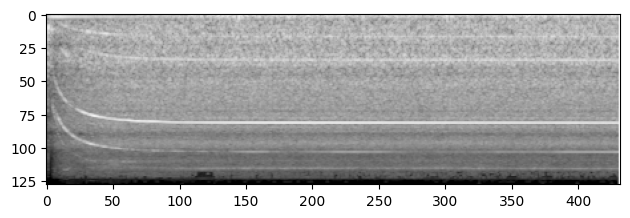

In [66]:
mel_spec, target = dataset[2]

show_img(mel_spec)

In [67]:
target

np.int64(36)